In [1]:
from datetime import date

today = date.today()
print(f'Last full compilation {today}')

Last full compilation 2023-06-02


# Cas de référence : échantillon monolithique

Nom de la campagne : `campagne_mono`



In [2]:
from classes import *
from funcData import *
import numpy as np
import matplotlib.pyplot as plt
from math import *
import os 

import matplotlib as mpl
mpl.rcParams['figure.dpi'] = 100

campagnes = ['campagne_mono']
# Can be long the first time
data = get_bulk_data(read_data_from_campaigns(campagnes))

Lecture des données réalisée en 0.03301s


## Taille de maille

On regarde:
- Les erreurs relative par coefficients avec deux maillages différents

Hypothèses de modélisations:
- 3D
- cylindres parfaits
- libres rotation

In [3]:

test_maillage_gros=data['mono_3D_mesh_1']
test_maillage_fin=data['mono_3D_mesh_2']


k_gros=np.array(test_maillage_gros.K_field_dic)
k_fin=np.array(test_maillage_fin.K_field_dic)

np.set_printoptions(precision=2)
print(f'Matrice d\'erreur des matrices K_field_dic [%]\n{100*(k_gros-k_fin)/k_fin}')

Matrice d'erreur des matrices K_field_dic [%]
[[-1.76e-02 -3.84e-02 -1.47e+02]
 [-2.55e-03  2.05e-02  4.13e+02]
 [ 5.40e+00 -4.01e+01  2.25e-01]]


Types d'éléments : Triangulaire prismatique quadratiques (15 noeuds)

Taille des maillages (éléments centraux/élément sur les bords) avec toujours 6 éléments dans l'epaisseur:
- Maillage 1 : 10mm/2.0mm (430 ddl)
- Maillage 2 : 7mm/0.8mm (2M ddl)

On remarque qu'il n'y a pas d'évolution significative pour ces tailles d'éléments. 
Nous choisirons le premier maillage (car nous auront également des calcul non lin à réaliser).

(J'ai fait tourner tous mes calcul avec le second maillage qui était finalement overkill pour ce que c'était...)



## Qualité des champs

Dans cette partie on regarde :
- la distibution des valeurs de contrainte par zone
- écart en déformation entre la consigne et ce qui est vraiment observé (à cause des cylindres incompressibles)

Hypothèses de modélisations :
- 3D
- Cylindres parfait
- Libre rotation des cylindres
- nu = 0.3, thickness = t = 30mm

In [4]:
def weighted_avg_and_std(values, weights):
    average = np.average(values, weights=weights)
    # Fast and numerically precise:
    variance = np.average((values-average)**2, weights=weights)
    return average, sqrt(variance)


def get_stress_average(root,folder_name, area, step_idx, porosity):
    elements_in_area = np.genfromtxt(root/'results'/folder_name / 'elements_per_area.csv', delimiter=',',
                                     deletechars='[]', skip_header=area-1, skip_footer=4-area, dtype='int')
    S_field = np.loadtxt(root/'results'/folder_name /
                         f'S_step-{step_idx}.csv', delimiter=',')
    s_values = []
    for element in elements_in_area[1:-1]:
        s_values.append(S_field[element])
    s_values = np.array(s_values)*(1-porosity)
    return s_values[:, 0]


def get_stress_average_whole_sample(root, folder_name, area, step_idx, porosity):
    S_field = np.loadtxt(root/'results'/folder_name /
                         f'S_step-{step_idx}.csv', delimiter=',')
    s_values = S_field[:]
    s_values = np.array(s_values)*(1-porosity)

    return s_values[:, 0]


<ipython-input-5-e006bfdcb7a8>:53: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


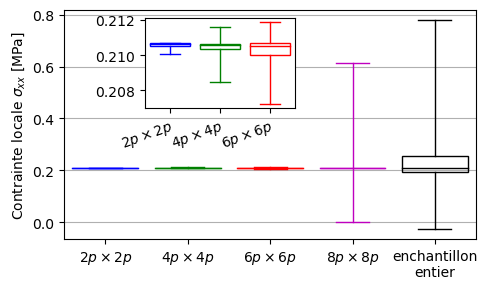

In [5]:
test = data['mono_3D_mesh_2']
campagne_folder = Path(f'../{campagnes[0]}')

porosity = 0.0

step_of_interest = 1
means = []
s_list = []
coeff_of_interest = 0
for area in range(1, 5):
    # print(f'area : {area}')
    s_values = get_stress_average(
        campagne_folder, test.test_id, area, step_of_interest, porosity)
    s_list.append(s_values)

s_values = get_stress_average_whole_sample(
    campagne_folder, test.test_id, None, step_of_interest, porosity)
s_list.append(s_values)


fig, ax1 = plt.subplots(figsize=(5, 3))
col = ['b', 'g', 'r', 'm', 'k']
for area in range(5):
    bp=plt.boxplot(s_list[area], patch_artist=True, whis=(0, 100),positions=[area] , 
                medianprops={'color': col[area]}, 
                boxprops={'color': col[area],'fill': False}, 
                capprops={'color': col[area]}, 
                flierprops = {'markeredgecolor': col[area]},
                whiskerprops={'color': col[area]},
                widths=0.8)

my_xticks = [r'$2p\times2p$', r'$4p\times4p$',
             r'$6p\times6p$', r'$8p\times8p$', f'enchantillon\nentier']
plt.ylabel(r'Contrainte locale $\sigma_{xx}$ [MPa]')
plt.xticks(np.arange(5), my_xticks)



plt.grid(axis='y')
ax2 = fig.add_axes([0.3, 0.62, 0.3, 0.3])
for area in range(3):
    plt.boxplot(s_list[area], patch_artist=True, whis=(0, 100),positions=[area] , 
                medianprops={'color': col[area]}, 
                boxprops={'color': col[area],'fill': False}, 
                capprops={'color': col[area]}, 
                flierprops = {'markeredgecolor': col[area]},
                whiskerprops={'color': col[area]},
                widths=0.8)
    
plt.xticks(rotation=20, ha="right", rotation_mode="anchor")
plt.xticks(np.arange(3), my_xticks[:3])

plt.tight_layout()
plt.savefig('images/stress_per_area.pdf')
plt.show()


<img src="images/area.png" width="400">

On remarque que la plage min max augmente avec la taille de la zonne mais la moyenne reste stable.

Step - 1
Consigne en déformation [0.02, 0.0, 0.0]
Déformation réelle (champ) [0.0211724810019029, 3.185437026523069e-05, -1.0680944424328482e-06]
Step - 2
Consigne en déformation [0.0, 0.02, 0.0]
Déformation réelle (champ) [3.048063066032216e-05, 0.021174775826313687, 1.4613081149826568e-07]

Step - 3
Consigne en déformation [0.0, 0.0, 0.01]
Déformation réelle (champ) [-2.0418376660516327e-06, -1.6557048131034258e-06, 0.009665425295931007]

Ecart de +5.9% en traction
Ecart de -3.3% en cisaillement


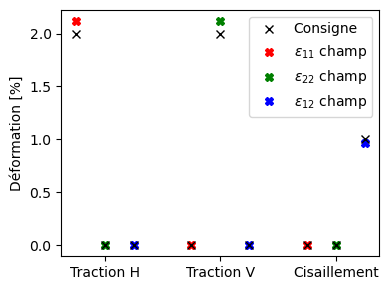

In [6]:
print(f'Step - 1')
print(f'Consigne en déformation {test.strain_th[0]}')
print(f'Déformation réelle (champ) {test.strain_field[0]}')
print(f'Step - 2')
print(f'Consigne en déformation {test.strain_th[1]}')
print(f'Déformation réelle (champ) {test.strain_field[1]}\n')
print(f'Step - 3')
print(f'Consigne en déformation {test.strain_th[2]}')
print(f'Déformation réelle (champ) {test.strain_field[2]}\n')

print(f'Ecart de {100*(test.strain_field[0][0]-test.strain_th[0][0])/test.strain_th[0][0]:+.1f}% en traction')
print(f'Ecart de {100*(test.strain_field[2][2]-test.strain_th[2][2])/test.strain_th[2][2]:+.1f}% en cisaillement')


strain_th=np.array(test.strain_th)
strain_field=np.array(test.strain_field)
plt.figure(figsize=(4,3))
plt.plot([],[],'kx', label='Consigne')
plt.plot([],[],'rX', label=r'$\epsilon_{11}$ champ')
plt.plot([],[],'gX', label=r'$\epsilon_{22}$ champ')
plt.plot([],[],'bX', label=r'$\epsilon_{12}$ champ')
plt.legend()

plt.plot([0,4,8],100*strain_field[:,0],'rX')
plt.plot([1,5,9],100*strain_field[:,1],'gX')
plt.plot([2,6,10],100*strain_field[:,2],'bX')

plt.plot([0,4,8],100*strain_th[:,0],'kx')
plt.plot([1,5,9],100*strain_th[:,1],'kx')
plt.plot([2,6,10],100*strain_th[:,2],'kx')



plt.xticks([1,5,9],['Traction H', 'Traction V', 'Cisaillement'])
plt.ylabel('Déformation [%]')
# plt.xlabel('Chargement')
plt.tight_layout()
plt.savefig('images/ecart_def_mono.pdf')

On remarque un écarts de déformation entre la consigne et la déformation obtenue par mesure de champs.Pour ce qui est de l'écart en traction, ce dernier peut s'expliquer par l'incompressibilité des cylindres. Si on tient effectivement de cet hypothèse, la déformation théorique est majorée de 7% (soit $\epsilon_{xx}=2.14\%$) ce qui n'est pas très loin des 6%.

L'écart en cisaillement est plus faible est est surement du à la sollicitation multiaxiale dans les coins. Il n'est pertinent ici de tenter de limiter cet écart dans la mesure où une mesure systèmatique de déformation par DIC sera réalisé pour plus de précision.

## Erreur dans une première configuration

Dans cette partie on regarde:
- Les différentes erreurs : Plane stress - KUBC(valeur champ) - KUBC(def champ + stress pantho)
- Les erreurs relatives par coefficients

Hypothèses de modélisations :
- 3D
- cylindres parfaits
- libre rotations
- nu = 0.3, t= 30mm

Hypothèses de modélisations:

Cas 3D, cylindres parfait + libre rotation + adhérence parfaite (U3=0)

In [7]:
test=data['mono_3D_mesh_2']

print('Erreur globale [%]')
print(f'Plane Stress - K(stress_field, strain_field):                   {test.get_error((0,1)):.1f}%')
print(f'K(stress_field, strain_field) - K(stress_panto, strain_field):  {test.get_error((1,2)):.1f}%')
print(f'Plane Stress - K(stress_panto, strain_field):                   {test.get_error((0,2)):.1f}%')

Erreur globale [%]
Plane Stress - K(stress_field, strain_field):                   0.5%
K(stress_field, strain_field) - K(stress_panto, strain_field):  2.7%
Plane Stress - K(stress_panto, strain_field):                   2.9%


Erreur par Coeff  [%] K11, K12, K33
Valeur Plane Stress: [9.89 2.97 3.46]MPa
Erreur Plane Stress - K(stress_field, strain_field)
[ 0.34  0.42 -0.76]
Erreur K(stress_field, strain_field) - K(stress_panto, strain_field)
[2.41 4.52 3.08]
Erreur Plane Stress - K(stress_panto, strain_field)
[2.76 4.96 2.3 ]


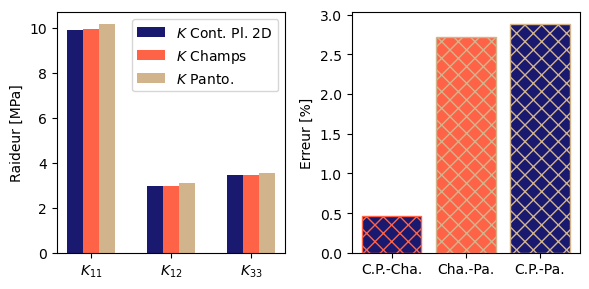

In [25]:
"""Sur les coeff"""
def det_err_coef(k_ref, k,coefs:tuple):
    return [100*(k[coef[0]][coef[1]]-k_ref[coef[0]][coef[1]])/k_ref[coef[0]][coef[1]] for coef in coefs]

k_ref=np.array(test.K_plane_stress)
k=np.array(test.K_field_dic)
print('Erreur par Coeff  [%] K11, K12, K33')
print(f'Valeur Plane Stress: {np.array([k_ref[0][0],k_ref[1][0],k_ref[2][2]])}MPa')
print('Erreur Plane Stress - K(stress_field, strain_field)')
print(f'{np.array(det_err_coef(k_ref, k,((0,0), (1,0), (2,2))))}')
k_ref=np.array(test.K_field_dic)
k=np.array(test.K_panto_dic)
print('Erreur K(stress_field, strain_field) - K(stress_panto, strain_field)')
print(f'{np.array(det_err_coef(k_ref, k,((0,0), (1,0), (2,2))))}')
k_ref=np.array(test.K_plane_stress)
k=np.array(test.K_panto_dic)
print('Erreur Plane Stress - K(stress_panto, strain_field)')
print(f'{np.array(det_err_coef(k_ref, k,((0,0), (1,0), (2,2))))}')


plt.figure(figsize=(6,3))
plt.subplot(121)
width=0.2
x=np.linspace(0,2,3)
plt.bar(x-0.2,[test.K_plane_stress[0][0],test.K_plane_stress[1][0],test.K_plane_stress[2][2]],
        width, color='midnightblue', label=r'$K$ Cont. Pl. 2D')
plt.bar(x,[test.K_field_dic[0][0],test.K_field_dic[1][0],test.K_field_dic[2][2]],
        width, color='tomato', label=r'$K$ Champs')
plt.bar(x+0.2,[test.K_panto_dic[0][0],test.K_panto_dic[1][0],test.K_panto_dic[2][2]],
        width, color='tan',  label=r'$K$ Panto.')

plt.legend()
plt.ylabel('Raideur [MPa]')
plt.xticks(range(3), [r'$K_{11}$',r'$K_{12}$',r'$K_{33}$'])



plt.subplot(122)
width=0.8
x=np.linspace(0,2,3)


plt.bar(0,[test.get_error((0,1))],
        width, color='midnightblue',edgecolor='tomato', hatch="xx")
plt.bar(1,[test.get_error((1,2))],
        width, color='tomato',edgecolor='tan', hatch="xx")
plt.bar(2,[test.get_error((0,2))],
        width, color='midnightblue',edgecolor='tan', hatch="xx")

plt.ylabel('Erreur [%]')
plt.xticks(range(3), ['C.P.-Cha.',
                      'Cha.-Pa.',
                      'C.P.-Pa.'])
plt.tight_layout()
plt.savefig('images/err_mono_coef.pdf')

## Effet de la libre rotation des cylindres


Hyposthèses de modélisations:
- 3D
- cylindre parfait
- nu = 0.3 et t = 30mm

In [9]:
test_free_rot=data['mono_3D_freerot_1']
test_no_free_rot=data['mono_3D_freerot_2']


print('Erreur globale [%] LIBRE BLOQUEE')
print(f'Plane Stress - K(stress_field, strain_field):                   {test_free_rot.get_error((0,1)):.1f}% {test_no_free_rot.get_error((0,1)):.1f}%')
print(f'K(stress_field, strain_field) - K(stress_panto, strain_field):  {test_free_rot.get_error((1,2)):.1f}% {test_no_free_rot.get_error((1,2)):.1f}%')
print(f'Plane Stress - K(stress_panto, strain_field):                   {test_free_rot.get_error((0,2)):.1f}% {test_no_free_rot.get_error((0,2)):.1f}%')

Erreur globale [%] LIBRE BLOQUEE
Plane Stress - K(stress_field, strain_field):                   0.5% 0.6%
K(stress_field, strain_field) - K(stress_panto, strain_field):  2.7% 3.3%
Plane Stress - K(stress_panto, strain_field):                   2.9% 3.9%


L'effet n'est pas significatif dans ce cas mais il est à priori important d'avoir le minimum de frottement type palier.

## Effets des défauts de la machine

Ici on regarde l'erreur en fonction des défauts introduit un par un.(IL MANQUE UNE SIMU)

Hypothèses de modélisations:
- 3D
- Libre rotation
- nu = 0.3 et t = 30mm

In [10]:

# * S: Stiffness
# * C: Clearance
# * F: Friction

test_S = data['mono_3D_defects_1']
test_SC = data['mono_3D_defects_2']
test_SCF = data['mono_3D_defects_3']
test_SCF_2 = data['mono_3D_defects_4']

print('Error Plane Stress - K(stress_panto, strain_field) [%]')
print(f'Stiffness                           {test_S.get_error((0,2)):.1f}%')
print(f'Stiffness + Clearance               {test_SC.get_error((0,2)):.1f}%')
print(f'Stiffness + Clearance + Friction    {test_SCF.get_error((0,2)):.1f}%')
print(f'Stiffness + Clearance + Friction 2  {test_SCF_2.get_error((0,2)):.1f}%')

Error Plane Stress - K(stress_panto, strain_field) [%]
Stiffness                           2.2%
Stiffness + Clearance               2.2%
Stiffness + Clearance + Friction    1.9%
Stiffness + Clearance + Friction 2  0.9%


Erreur par Coeff  [%] K11, K12, K33
Valeur Plane Stress: [10.16  3.11  3.54]MPa
Erreur Plane Stress - K(stress_panto, strain_field)
[-3.21 -4.37 -3.56]


No handles with labels found to put in legend.


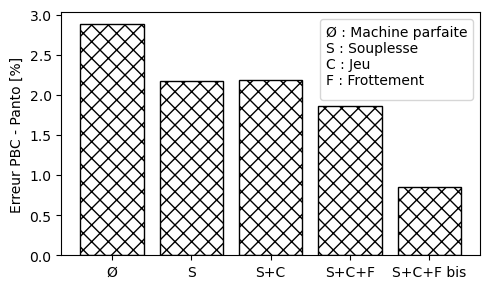

In [11]:
k_parfat = test_free_rot.K_panto_dic
k_defauts = test_SCF_2.K_panto_dic

k_ref = np.array(k_parfat)
k = np.array(k_defauts)
print('Erreur par Coeff  [%] K11, K12, K33')
print(
    f'Valeur Plane Stress: {np.array([k_ref[0][0],k_ref[1][0],k_ref[2][2]])}MPa')
print('Erreur Plane Stress - K(stress_panto, strain_field)')
print(f'{np.array(det_err_coef(k_ref, k,((0,0), (1,0), (2,2))))}')


plt.figure(figsize=(5,3))
width=0.8
x=np.linspace(0,4,5)

plt.bar(x,[test_free_rot.get_error((0,2)),test_S.get_error((0,2)),
           test_SC.get_error((0,2)),test_SCF.get_error((0,2)),test_SCF_2.get_error((0,2))],
        width, color='k',fill=False, hatch='xx')

plt.ylabel(r'Erreur PBC - Panto [%]')
plt.xticks(range(5), ['Ø', 'S', 'S+C', 'S+C+F', 'S+C+F bis'])
plt.legend(title='Ø : Machine parfaite\nS : Souplesse\nC : Jeu\nF : Frottement')
plt.tight_layout()
plt.savefig('images/defauts_mono.pdf')

Les défauts assouplient les raideurs (c'est logique) et comme le KUBC conduisait à une raideur plus importante sans défauts, l'erreur finale est plus faible avec les défauts.

## Influence de l'epaisseur et du coefficient de Poisson

Ici on regarde l'erreur avec différents coefficients de Poisson : 0.01 et 0.49, et différentes épaisseur : 10 et 50mm.

Hypothèses de modélisations:
- 3D
- cylindres parfaits
- libres rotation
  

Erreur Plane Stress - K(stress_pantho, strain_field)
nu = 0.01 t = 10mm      2.6%
nu = 0.01 t = 50mm      2.6%
nu = 0.49 t = 10mm      2.5%
nu = 0.49 t = 50mm      4.8%
matrice Plane stress nu = 0.01:
[[9.   0.09 0.  ]
 [0.09 9.   0.  ]
 [0.   0.   4.46]]
matrice Plane stress nu = 0.49:
[[11.84  5.8   0.  ]
 [ 5.8  11.84  0.  ]
 [ 0.    0.    3.02]]


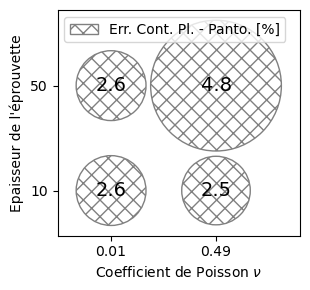

In [12]:

test_nut_1 = data['mono_3D_nuT_1']
test_nut_2 = data['mono_3D_nuT_2']
test_nut_3 = data['mono_3D_nuT_3']
test_nut_4 = data['mono_3D_nuT_4']

err0 = test_nut_1.get_error((0,2))
err1 = test_nut_2.get_error((0,2))
err2 = test_nut_3.get_error((0,2))
err3 = test_nut_4.get_error((0,2))

print('Erreur Plane Stress - K(stress_pantho, strain_field)')
print(f'nu = 0.01 t = 10mm      {err0:.1f}%')
print(f'nu = 0.01 t = 50mm      {err1:.1f}%')
print(f'nu = 0.49 t = 10mm      {err2:.1f}%')
print(f'nu = 0.49 t = 50mm      {err3:.1f}%')

print('matrice Plane stress nu = 0.01:')
print(np.array(test_nut_1.K_plane_stress))
print('matrice Plane stress nu = 0.49:')
print(np.array(test_nut_3.K_plane_stress))

fac=0.13
circle1 = plt.Circle((0, 0), fac*err0, color='0.5', fill=False, hatch='xx')
circle2 = plt.Circle((0, 1), fac*err1, color='0.5', fill=False, hatch='xx')
circle3 = plt.Circle((1, 0), fac*err2, color='0.5', fill=False, hatch='xx')
circle4 = plt.Circle((1, 1), fac*err3, color='0.5', fill=False, hatch='xx')

plt.figure(figsize=(3.2,3))
ax = plt.gca()

plt.text(0,0, f'{err0:.1f}', ha='center', va='center', size='14')
plt.text(0,1, f'{err1:.1f}', ha='center', va='center', size='14')
plt.text(1,0, f'{err2:.1f}', ha='center', va='center', size='14')
plt.text(1,1, f'{err3:.1f}', ha='center', va='center', size='14')

ax.add_patch(circle1)
ax.add_patch(circle2)
ax.add_patch(circle3)
ax.add_patch(circle4)

plt.axis('equal')
plt.xticks([0,1], [0.01, 0.49])
plt.xlabel(r'Coefficient de Poisson $\nu$')
plt.yticks([0,1], [10,50])
plt.ylabel('Epaisseur de l\'éprouvette')
plt.legend([r'Err. Cont. Pl. - Panto. [%]'], loc=2)


plt.tight_layout()
plt.savefig('images/err_nu_t_mono.pdf')

le fait que l'erreur est plus petite pour nu=0.49 et t=10mm que nu=0.01 viens du fait que les coefficient de la matrice ne sont pas égaux. Le terme max de la matrice avec nu=0.49 est plus élevé que celui avec nu=0.01 (cf méthode de calcul de l'err).

In [13]:
k_ref = np.array(test_nut_1.K_panto_dic)
k = np.array(test_nut_2.K_panto_dic)
print('Comparaison des matrices K_panto_dic obtenue avec différents nu et t (err relative des termes K11 K12 et K33)')
print('nu = 0.01 et t=10 et 50 mm (référence à 10mm)')
print(f'{np.array(det_err_coef(k_ref, k,((0,0), (1,0), (2,2))))}')

k_ref = np.array(test_nut_3.K_panto_dic)
k = np.array(test_nut_4.K_panto_dic)

print('nu = 0.49 et t=10 et 50 mm (référence à 10mm)')
print(f'{np.array(det_err_coef(k_ref, k,((0,0), (1,0), (2,2))))}')

Comparaison des matrices K_panto_dic obtenue avec différents nu et t (err relative des termes K11 K12 et K33)
nu = 0.01 et t=10 et 50 mm (référence à 10mm)
[ 0.    0.04 -0.  ]
nu = 0.49 et t=10 et 50 mm (référence à 10mm)
[2.12 3.32 1.48]


A nu=0.01 t n'as pas beaucoup d'influence. Ca va bien dans le sens logique des choses. Pas vraiment de surprise.

## Passage de 3D à 2D plane stress

Etant donné que les matériaux qui seront étudiés auront à priori un coefficient de Poisson relativement faible, on quantifie l'erreur du passage à 2D plane stress. (C'est pour aléger les calculs évidement car il y aurait trop de ddl pour une structure 3D avec des structures en lattice).

Hypothèses de modélisations communes:
- cylindres parfaits
- libre rotation
- nu = 0.3 et t = 30mm

3 tests:
- Cas 3D adhérence cylindres-éprouvette parfaite (U3 = 0 à l'interface) 
- Cas 3D sans friction à l'interface (U3 libre à l'interface)
- Cas 2D Hyp contrainte plane




In [14]:

test_3D = data['mono_3D_PS_1']
test_3D_U3 = data['mono_3D_PS_2']
test_2D = data['mono_3D_PS_3']

print('Erreur Plane Stress - K(stress_field, strain_field)')
print(f'3D          {test_3D.get_error((0,2)):.1f}%')
print(f'3D free U3  {test_3D_U3.get_error((0,2)):.1f}%')
print(f'2D          {test_2D.get_error((0,2)):.1f}%')


Erreur Plane Stress - K(stress_field, strain_field)
3D          2.9%
3D free U3  2.4%
2D          2.3%


Le cas 1 correspond au modèle 3D avec adhérence parfaite entre l'éprouvette et les cylindres alors que le second test suppose une friction nulle.

In [15]:
k_3d_u3 = test_3D_U3.K_panto_dic
k_2d = test_2D.K_panto_dic

k_ref = np.array(k_2d)
k = np.array(k_3d_u3)
print('Erreur par Coeff  [%] K11, K12, K33')

print('Erreur des coeff de K(stress_panto, strain_field) entre 3D free U3 et 2D')
print(f'{np.array(det_err_coef(k_ref, k,((0,0), (1,0), (2,2))))}')

Erreur par Coeff  [%] K11, K12, K33
Erreur des coeff de K(stress_panto, strain_field) entre 3D free U3 et 2D
[ 0.02 -0.09  0.43]


C'est très proche -> OK

## Amélioration de la géométrie

Les images sont pas présentes ici mais on observe des déformation et niveau de contrainte important entre les cylindres et la contrainte hydrostatique est élevé dans (ou basse) dans les coins -> faire des entailles pour améliorer les BC. 
Aussi montrer que les efforts dans les cylindres des coins est beaucoup plus élévé et donc on a intêret à les soulager pour pouvoir chager de manière plus important l'éprouvette (si on le souhaite bien sûr).

On étudie donc ici l'erreur lié à la présence d'entailles dans les coins.

Hypothèses de modélisation:
- 3D
- cylindres parfaits
- Libre rotations
- nu = 0.3 et t = 30mm

<img src="images/cisaillement_MONO_1.png" width="500">
<img src="images/s11_step0_MONO_1.png" width="500">
<img src="images/cisaillement_MONO_3.png" width="500">

In [16]:

test_no_CC= data['mono_2D_CC_1']
test_CC = data['mono_2D_CC_2']

print('Erreur Plane Stress - K(stress_field, strain_field)')
print(f'Sans CC     {test_no_CC.get_error((0,2)):.1f}%')
print(f'Avec CC     {test_CC.get_error((0,2)):.1f}%')


k_ref = np.array(test_no_CC.K_plane_stress)
k = np.array(test_no_CC.K_panto_dic)

print('Err relative par coeff (K11, K12, K33)')
print('SANS CC')
print(f'{np.array(det_err_coef(k_ref, k,((0,0), (1,0), (2,2))))}')

k = np.array(test_CC.K_panto_dic)
print('AVEC CC')
print(f'{np.array(det_err_coef(k_ref, k,((0,0), (1,0), (2,2))))}')

print('Matrice de raideur plane stress')
print(k_ref)

Erreur Plane Stress - K(stress_field, strain_field)
Sans CC     2.3%
Avec CC     0.9%
Err relative par coeff (K11, K12, K33)
SANS CC
[2.31 3.81 1.65]
AVEC CC
[0.72 2.56 0.1 ]
Matrice de raideur plane stress
[[9.89 2.97 0.  ]
 [2.97 9.89 0.  ]
 [0.   0.   3.46]]


Net amélioration avec les entailles en particulier pour les coef Kii

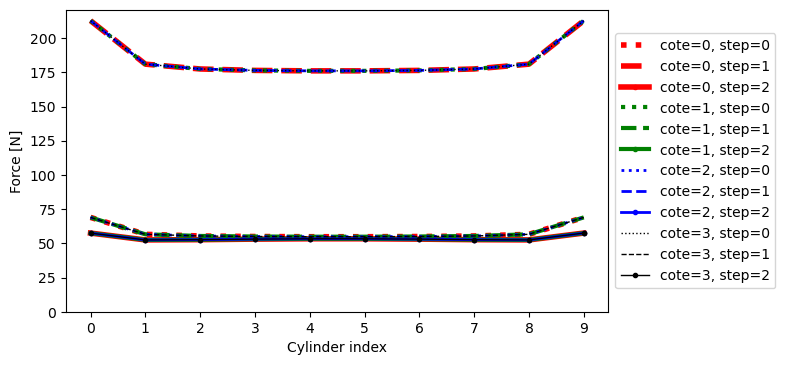

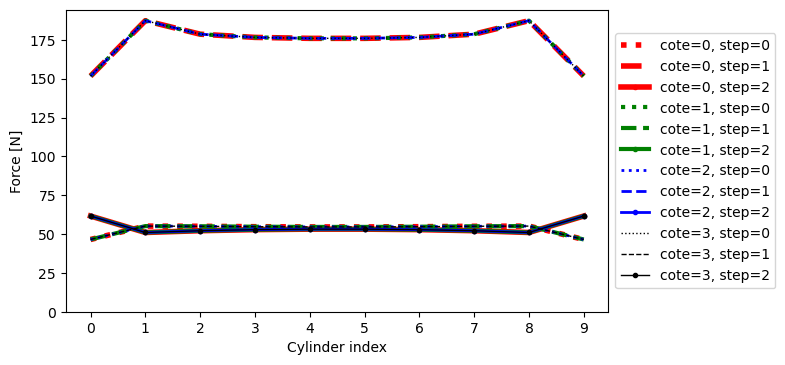

In [17]:

# ! QUE POUR LES CALCULS LIN

def get_norm(x, y) -> float:
    return sqrt(x**2+y**2)

def plot_forces(test):
    time_step, extracted_disp_and_force = test.get_forces()
    rf = extracted_disp_and_force['TBC']

    rf_norm = np.zeros((4, 10, 3))
    for cote in range(4):
        for cyl in range(10):
            if len(rf[cote*12*4+cyl*12]) != 0:
                rf_norm[cote, cyl, :] = np.array([get_norm(rf[cote*12*10+cyl*12][1], rf[cote*12*10+cyl*12+1][1]),
                                        get_norm(rf[cote*12*10+cyl*12][2], rf[cote*12*10+cyl*12+1][2]),
                                        get_norm(rf[cote*12*10+cyl*12][3], rf[cote*12*10+cyl*12+1][3])])

    plt.figure(figsize=(7,4))
    color=['r', 'g', 'b', 'k']
    style=[':', '--', '.-']
    for cote in range(4):
        for step in range(3):
            plt.plot(range(10), rf_norm[cote, :, step], color[cote]+style[step], label=f'{cote=}, {step=}', lw=4-cote)
    plt.xlabel('Cylinder index')
    plt.ylabel('Force [N]')
    plt.xticks(range(10))
    plt.ylim(bottom=0)
    plt.legend()
    plt.legend(loc='center left', bbox_to_anchor=(1, 0.5))

plot_forces(data['mono_2D_CC_1'])
plot_forces(data['mono_2D_CC_2'])

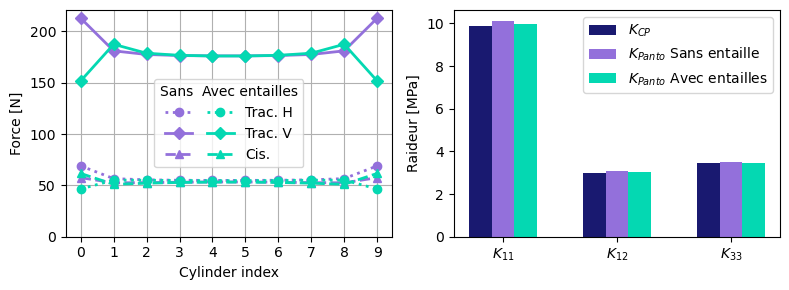

In [18]:

# ! QUE POUR LES CALCULS LIN

def get_norm(x, y) -> float:
    return sqrt(x**2+y**2)

def plot_forces(test,color=None,opt=None):
    time_step, extracted_disp_and_force = test.get_forces()
    rf = extracted_disp_and_force['TBC']

    rf_norm = np.zeros((4, 10, 3))
    for cote in range(4):
        for cyl in range(10):
            if len(rf[cote*12*4+cyl*12]) != 0:
                rf_norm[cote, cyl, :] = np.array([get_norm(rf[cote*12*10+cyl*12][1], rf[cote*12*10+cyl*12+1][1]),
                                        get_norm(rf[cote*12*10+cyl*12][2], rf[cote*12*10+cyl*12+1][2]),
                                        get_norm(rf[cote*12*10+cyl*12][3], rf[cote*12*10+cyl*12+1][3])])

    if not opt:
        cc_status='Sans entaille'
        chgmt=[' ',' ', ' ']
        
    else:
        cc_status='Avec entaille'
        chgmt=['Trac. H','Trac. V', 'Cis.']
    style=['o:', 'D-', '^--']
    
    for cote in range(1):
        for step in range(3):
            plt.plot(range(10), rf_norm[cote, :, step], style[step], color=color[cote], lw=2-cote, label=f'{chgmt[step]}')
    plt.xlabel('Cylinder index')
    plt.ylabel('Force [N]')
    plt.xticks(range(10))
    plt.ylim(bottom=0)

    
    

plt.figure(figsize=(8,3))
plt.subplot(121)
plot_forces(data['mono_2D_CC_1'], color=['mediumpurple'])
plot_forces(data['mono_2D_CC_2'], color=['#04D8B2'],opt=True)
plt.grid()

# plt.legend(loc='center left', bbox_to_anchor=(1, 0.5), ncol=2, title='Sans'+' '*10+'Avec ')
plt.legend(loc=10, ncol=2, title='Sans'+' '*2+'Avec entailles',columnspacing=-0.1,)


plt.subplot(122)

test_no_CC= data['mono_2D_CC_1']
test_CC = data['mono_2D_CC_2']
k_ref = np.array(test_no_CC.K_plane_stress)
k = np.array(test_no_CC.K_panto_dic)


width=0.2
x=np.linspace(0,2,3)
plt.bar(x-0.2,[test_no_CC.K_plane_stress[0][0],test_no_CC.K_plane_stress[1][0],test_no_CC.K_plane_stress[2][2]],
        width, color='midnightblue', label=r'$K_{CP}$')
plt.bar(x,[test_no_CC.K_panto_dic[0][0],test_no_CC.K_panto_dic[1][0],test_no_CC.K_panto_dic[2][2]],
        width, color='mediumpurple', label=r'$K_{Panto}$ Sans entaille')
plt.bar(x+0.2,[test_CC.K_panto_dic[0][0],test_CC.K_panto_dic[1][0],test_CC.K_panto_dic[2][2]],
        width, color='#04D8B2',  label=r'$K_{Panto}$ Avec entailles')

plt.legend()
plt.ylabel('Raideur [MPa]')
plt.xticks(range(3), [r'$K_{11}$',r'$K_{12}$',r'$K_{33}$'])

plt.tight_layout()
plt.savefig('images/effort_cylin_cc_effect.pdf')


In [19]:
test_2D = data['mono_3D_PS_3']
kref=   np.array(test_2D.K_plane_stress)
k=      np.array(test_2D.K_panto_dic)

print(kref)
print(k-kref)
print(test_2D.get_error((0,2)))

[[9.89 2.97 0.  ]
 [2.97 9.89 0.  ]
 [0.   0.   3.46]]
[[ 2.29e-01  1.09e-01 -3.47e-04]
 [ 1.13e-01  2.25e-01  2.92e-04]
 [-3.39e-05  4.10e-04  5.73e-02]]
2.3222882237994655


In [20]:

campagnes = ['campagne_test']
# Can be long the first time
data = get_bulk_data(read_data_from_campaigns(campagnes))

print(data['Z_test_honey_5'].get_error((0,3)))
print(data['Z_test_honey_6'].get_error((0,3)))
print(data['Z_test_honey_7'].get_error((0,3)))
print(data['Z_test_honey_8'].get_error((0,3)))

print(data['Z_test_honey_5'].K_field_dic[0])
print(data['Z_test_honey_6'].K_field_dic[0])
print(data['Z_test_honey_7'].K_field_dic[0])
print(data['Z_test_honey_8'].K_field_dic[0])


k5=np.array(data['Z_test_honey_5'].K_field_dic)
k6=np.array(data['Z_test_honey_6'].K_field_dic)
k7=np.array(data['Z_test_honey_7'].K_field_dic)

k_ref = np.array(data['Z_test_honey_8'].K_field_dic)

print(f'{np.array(det_err_coef(k_ref, k5,((0,0), (1,0), (2,2))))}')
print(f'{np.array(det_err_coef(k_ref, k6,((0,0), (1,0), (2,2))))}')
print(f'{np.array(det_err_coef(k_ref, k7,((0,0), (1,0), (2,2))))}')


print('- '*10)
print(data['Z_test_honey_5'].strain_field)
print(data['Z_test_honey_6'].strain_field)
print(data['Z_test_honey_7'].strain_field)
print(data['Z_test_honey_8'].strain_field)

Lecture des données réalisée en 0.00570s
3.1996942673932725
3.1567243591039813
3.5103961025294734
3.392209425507803
[13.858494088308587, 10.891038652751186, 0.0007237788978420065]
[13.821647432009142, 10.856279685755933, 0.0018988976535002438]
[13.80460092821428, 10.809890028261288, -0.001002483839870615]
[13.64785766830367, 10.7377144376665, 0.003763123288609202]
[1.54 0.19 1.82]
[1.27 0.25 1.97]
[1.15 0.41 0.32]
- - - - - - - - - - 
[[0.020466893133764995, -0.002251134171791877, 1.4433179759795918e-06], [-0.0007067086177988733, 0.020003813028107827, 6.850342879994448e-06], [2.892272582930887e-06, -8.509245873183219e-07, 0.010163729001552185]]
[[0.0204914253033068, -0.0022592470943920704, 1.4971819005198204e-05], [-0.0006880474541608648, 0.01995123561565418, 1.1244860354314365e-05], [4.9374311119889646e-06, 3.835197937371998e-07, 0.01017233130571865]]
[[0.020165556605207458, -0.002166907574929343, 1.9873018756396722e-06], [-0.0008941588207780482, 0.020015009855949686, 1.39436497801660